# 03 · Ingeniería de variables y base analítica

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 2 (preparación analítica)

## A. Contexto de la etapa

**¿Qué hacemos?** Construimos la **base analítica**: una tabla con una fila por pieza del Skinpass, con las variables derivadas en su versión formal, las reglas de extremos y faltantes, y las particiones de validación. Todos los modelos (Notebooks 04 a 07) leerán esta misma tabla.

**¿Por qué ahora y por qué así?** Hasta aquí las variables derivadas eran exploratorias. Antes de modelar hay que **fijar las reglas por escrito**, para no ajustarlas después según convenga a los resultados. Es la misma lógica del plan de análisis: decidir antes de mirar.

**Decisiones aprobadas que se aplican aquí** (2026-11-28):
1. **Enfoque de la tesis:**
   - **ΔBending:** cuánto explica el MC4 frente al Skinpass.
   - **Defectos de forma:** probar el camino corona → fuerza real → forma.
   - **Aparte:** peso (intervención A), sesgo del preset (D) y días de espera.
2. **Extremos:** no se borran piezas. Se **recorta** el valor a un límite y se agrega una **bandera**.
3. **Prueba final:** noviembre y diciembre de 2025 quedan reservados y no se usan hasta el final.

## B. Fundamento conceptual

**1. Ingeniería de variables con razón física.** Una variable derivada vale la pena si representa un mecanismo del proceso. Por ejemplo, la *corona relativa* (corona / espesor) compara el perfil de láminas de distinto espesor: 60 µm de corona es mucho en 1.5 mm y poco en 8 mm. Cada variable de este notebook lleva su razón física en el diccionario.

**2. Recorte (winsorización) con bandera.** Recortar es reemplazar los valores por encima del percentil 99.5 por ese percentil (y lo mismo abajo con el 0.5). La pieza se conserva, pero un valor extremo ya no domina un promedio ni una pendiente. La **bandera** (0/1) conserva la información de que algo raro pasó, porque un evento extremo puede ser justo la causa de un defecto.

**3. Fuga de información en los límites.** Los percentiles para recortar se calculan **solo con los datos de entrenamiento**. Si se calcularan con todo, la regla ya "sabría" algo del periodo de prueba. Esto aplica a cualquier transformación aprendida de los datos: medias, medianas para imputar, escalas.

**4. Faltantes: dónde se imputan.** La base guarda los faltantes como faltantes. La imputación se hace **dentro de cada modelo** y solo con entrenamiento: GBDT maneja los faltantes de forma nativa; el modelo lineal imputa con la mediana del producto y agrega una bandera de faltante. Imputar aquí con toda la base sería otra fuga.

**5. Momento en que se conoce cada variable.** Para cada predictor anotamos **cuándo existe** el dato: al salir del MC4, al llegar al Skinpass, durante el proceso del Skinpass o después del dictamen. Una variable que existe después del resultado no puede explicarlo (fuga). Una que existe durante el proceso puede ser **mediadora** pero no **causa inicial**.

**6. Validación agrupada y temporal.** Las piezas de un mismo programa del MC4 comparten rodillos, horno y campaña. Si unas quedan en entrenamiento y otras en validación, el modelo "reconoce" el programa y la validación sale optimista. Por eso los pliegues se arman **por Programa MC4** (que además mantiene juntas las piezas de un mismo rollo). El periodo de prueba (noviembre-diciembre) verifica que lo aprendido se sostiene en datos posteriores.

## C. Objetivo y metodología

| # | Paso | Resultado |
|---|---|---|
| 1 | Partir el tiempo: entrenamiento (enero-octubre) y prueba (noviembre-diciembre) | Bandera `en_prueba`; programas que cruzan la frontera |
| 2 | Variables derivadas por bloque, con razón física | Columnas de respuesta, MC4, SKP y controles |
| 3 | Reglas de extremos: límites físicos y percentiles de entrenamiento | Variables recortadas + banderas + tabla de umbrales |
| 4 | Faltantes | Cobertura por variable; banderas de faltante donde importa |
| 5 | Auditoría de fuga | Momento en que se conoce cada predictor y su uso permitido |
| 6 | Poblaciones y pliegues | Población A, B; 5 pliegues por Programa MC4 |
| 7 | Guardar | `data/analitica/base_analitica.parquet` y diccionario |

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [4]:
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 40, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)
ANALITICA = RAIZ / 'data' / 'analitica'; ANALITICA.mkdir(exist_ok=True)
M = lambda c: f'{c} MC4'
FECHA_PRUEBA = pd.Timestamp('2025-11-01')

In [5]:
# Datos originales (no se modifican) y join pieza → rollo.
mc4, skp = cargar_mc4(), cargar_skp()
L = unir_mc4_skp(mc4, skp).sort_values('Fecha Inicio').reset_index(drop=True)
num = lambda c: pd.to_numeric(L[c], errors='coerce')
print(f'Piezas ligadas: {len(L):,}')

Piezas ligadas: 57,099


### 1. Partición temporal
La prueba final usa la fecha en que la pieza **entra al Skinpass**. Antes de construir variables marcamos qué piezas son de prueba, porque los umbrales se calculan sin ellas.

In [6]:
B = pd.DataFrame(index=L.index)
B['pieza'] = L['Material Salida']
B['rollo'] = L['Material Entrada']
B['fecha'] = L['Fecha Inicio']
B['en_prueba'] = B['fecha'] >= FECHA_PRUEBA
ENTR = ~B['en_prueba']

prog = L[M('Programa')].astype('Int64').astype(str)
cruza = prog.groupby(prog).transform(lambda s: B.loc[s.index, 'en_prueba'].nunique() > 1)
print(f"Entrenamiento: {ENTR.sum():,} piezas ({ENTR.mean():.1%}) · prueba: {(~ENTR).sum():,} ({(~ENTR).mean():.1%})")
print(f"Programas MC4 con piezas a los dos lados de la frontera: {prog[cruza].nunique()} ({cruza.sum()} piezas)")

Entrenamiento: 47,461 piezas (83.1%) · prueba: 9,638 (16.9%)
Programas MC4 con piezas a los dos lados de la frontera: 52 (1884 piezas)


**Programas que cruzan la frontera.** Un programa laminado a fines de octubre puede llegar al Skinpass en noviembre. Sus piezas comparten el programa, así que una parte del programa estaría en entrenamiento y otra en prueba. Son pocas piezas; las marcamos con `frontera` y en la evaluación final se reporta el resultado con y sin ellas.

In [7]:
B['frontera'] = cruza.values

### 2. Variables derivadas por bloque
Cada bloque corresponde a una parte de la tesis. Las fórmulas y la razón física de cada variable quedan en el diccionario (sección 7).

In [8]:
# ---- Identificación, agrupaciones y controles
B['programa_mc4'] = prog.values
B['programa_skp'] = L['Programa'].astype(str)
B['colada'] = L[M('Colada')].astype(str)
B['rodillo'] = L['Rodillo de Trabajo'].astype(str)
B['campana'] = (L['Rodillo de Trabajo'] != L['Rodillo de Trabajo'].shift()).cumsum()
B['usuario_skp'] = L['Usuario'].astype(str)
B['norma'] = L['Norma'].astype(str)
B['grado_salida'] = L['Grado Salida'].astype(str)
B['pram'] = L['PRAM'].astype(str)
B['rango_espesor'] = pd.cut(L['Espesor Entrada'], CORTES_ESPESOR_MM).astype(str)
B['producto'] = B['norma'] + ' | ' + B['grado_salida'] + ' | ' + B['rango_espesor']
B['rango_ancho'] = pd.cut(L['Ancho Entrada'], [0, 1000, 1150, 1300, 1450, 1600, 3000]).astype(str)
B['modo'] = L['Modo Molino'].astype(str)
B['espesor_mm'] = L['Espesor Entrada']
B['ancho_mm'] = L['Ancho Entrada']
B['espesor_final_nominal_mm'] = L[M('Espesor Final')]          # especificación del producto final (Notebook 01)
B['peso_entrada_t'] = L['Peso Entrada'] / 1000
B['dividido'] = L['Dividido'].eq('SI').astype(int)
B['es_reproceso'] = L['Es Reproceso'].astype(int)
B['holgura_peso_pct'] = 100 * (L['Peso Máximo'] - L['Peso Entrada']) / L['Peso Máximo']
B['excede_peso_orden'] = (L['Peso Entrada'] > L['Peso Máximo']).astype(int)

# ---- Respuesta A: esfuerzo del Skinpass
B['delta_bending'] = L[RB] - L[PB]
B['delta_fuerza'] = L[RF] - L[PF]
B['fuerza_real'] = L[RF]
B['bending_real'] = L[RB]
B['preset_fuerza'] = L[PF]
B['preset_bending'] = L[PB]
B['delta_fuerza_pct'] = 100 * B['delta_fuerza'] / L[PF].where(L[PF] != 0)
B['delta_back'] = L[RBK] - L[PBK]
B['delta_front'] = L[RFR] - L[PFR]
B['elongacion'] = L['Elongación']

# ---- MC4 geometría (herencia)
cor = num(M('Corona Salida'))
B['corona_um'] = cor.where(cor.between(0, 1000))                 # regla física: fuera de 0-1000 µm es imposible
B['corona_relativa_pct'] = 100 * B['corona_um'] / (1000 * num(M('Espesor')))
B['acunamiento_um'] = num(M('Acuñamiento Salida'))
B['taper_medido'] = num(M('Taper Medido'))                       # Taper Teórico vale 0 siempre
B['error_espesor_um'] = 1000 * (num(M('Espesor')) - num(M('Espesor Objetivo')))
B['error_ancho_mm'] = num(M('Ancho')) - num(M('Ancho Objetivo'))
amin, amax = num(M('Ancho Mínimo')), num(M('Ancho Máximo'))
B['posicion_tol_ancho'] = ((num(M('Ancho')) - amin) / (amax - amin)).where(amax > amin)
B['canteo_r1'] = num(M('Canteo R1'))
B['canteo_r2'] = num(M('Canteo R2'))
B['offset_ancho_manual_aplicado'] = (num(M('Offset de Ancho Manual ')).fillna(0) != 0).astype(int)

# ---- MC4 térmica (herencia)
B['error_t_enrollado_c'] = num(M('Temp Enrollado Real')) - num(M('Temp Enrollado Obj'))
B['error_t_acabado_c'] = num(M('Temp Acabado Real')) - num(M('Temp Acabado Obj'))
B['enrollado_fuera_rango'] = (~num(M('Temp Enrollado Real')).between(num(M('Temp Enrollado Min')), num(M('Temp Enrollado Max')))
                              & num(M('Temp Enrollado Min')).notna()).astype(int)
B['t_f1_c'] = num(M('Temp. F1'))
B['caida_f1_f7_c'] = num(M('Temp. F1')) - num(M('Temp. F7'))
B['asimetria_acabador_c'] = (num(M('Temp. Acabador Sup. A')) - num(M('Temp. Acabador Sup. B'))).abs()
looper = pd.concat([num(M(f'Tensión de Looper {i} [Mpa]')) for i in range(1, 7)], axis=1)
B['looper_media_mpa'] = looper.mean(axis=1)
B['looper_max_mpa'] = looper.max(axis=1)
desc = num(M('Temperatura Descarga Salida'))
B['t_descarga_horno_c'] = desc.where(desc > 0)                   # 0 °C es un código de faltante
B['tiempo_estancia_horno'] = num(M('Tiempo Estancia'))            # unidad no documentada (mediana 173)
B['cubierta_termica_pct'] = num(M('% Uso Cubierta Térmica'))
B['dias_mc4_skp'] = (L['Fecha Inicio'] - L[M('Fecha Fin')]).dt.total_seconds() / 86400

# ---- SKP rodillos y operación
B['piezas_en_campana'] = B.groupby('campana').cumcount() + 1     # desgaste dentro de la campaña (usar con ancho)
B['diametro_rodillo_mm'] = L['Rodillo de Trabajo Diám. Entrada']   # vida del rodillo (baja con cada rectificado)
B['dif_diametro_pareja_mm'] = (L['Rodillo de Trabajo Diám. Entrada'] - L['Rodillo de Trabajo Pareja Diám. entrada']).abs()
B['corona_rodillo'] = L['Rodillo de Trabajo Corona Entrada']       # unidad no documentada
B['diametro_apoyo_sup_mm'] = L['Rodillo Apoyo Superior Diám.']
B['riesgo_spring_back'] = L['Riesgo de Spring Back'].eq('SI').astype(int)
print(f'Columnas construidas: {B.shape[1]}')

Columnas construidas: 64


**Variables que la propuesta sugería y no se construyen:**
- **Desajuste de corona banda-rodillo.** La corona de la banda está en µm, pero la unidad de `Rodillo de Trabajo Corona Entrada` no está documentada (valores de 0 a 0.12). Combinarlas sin conocer la unidad sería inventar una relación. Se conserva la corona del rodillo por separado.
- **Fuerza específica (fuerza / ancho × elongación).** En modo Elongación la elongación es la consigna del producto (el producto explica el 95 % de su varianza), así que dividir entre ella no aporta información pieza a pieza. Se usa la fuerza real con el ancho como control.
- **Toneladas en campaña.** Es la misma señal que piezas en campaña (ρ = 0.98).
- **Temperaturas F2 a F7 por separado.** Quedan resumidas en T en F1 y la caída F1→F7.

### 3. Reglas de extremos
Dos tipos de regla:
- **Física**, cuando el valor es imposible: corona fuera de 0-1,000 µm y descarga del horno a 0 °C pasan a faltante (ya aplicado arriba).
- **Estadística**, para valores posibles pero extremos: se recortan a los percentiles 0.5 y 99.5 **del entrenamiento** y se marca una bandera.

El error de temperatura de enrollado tiene, además, una regla con significado de proceso: más de 100 °C por debajo del objetivo es un **enrollado frío**, un evento que puede importar por sí mismo.

In [9]:
RECORTAR = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm',
            'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c', 'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa',
            'tiempo_estancia_horno', 'dias_mc4_skp', 'canteo_r1', 'canteo_r2']
umbrales = {}
for c in RECORTAR:
    lo, hi = B.loc[ENTR, c].quantile([.005, .995])           # solo entrenamiento
    umbrales[c] = (lo, hi)
    fuera = (B[c] < lo) | (B[c] > hi)
    B[f'{c}_extremo'] = fuera.astype(int)
    B[c] = B[c].clip(lo, hi)

# Enrollado frío: regla de proceso (no de percentil).
B['enrollado_frio'] = (B['error_t_enrollado_c'] < -100).astype(int)
B['error_t_enrollado_c'] = B['error_t_enrollado_c'].clip(lower=-100, upper=B.loc[ENTR, 'error_t_enrollado_c'].quantile(.995))
umbrales['error_t_enrollado_c'] = (-100.0, B['error_t_enrollado_c'].max())

tab_umb = pd.DataFrame([{'variable': c, 'límite inferior': lo, 'límite superior': hi,
                         'piezas recortadas (entrenamiento y prueba)': int(B.get(f'{c}_extremo', B['enrollado_frio'] if c == 'error_t_enrollado_c' else 0).sum())}
                        for c, (lo, hi) in umbrales.items()])
tab_umb.round(3).to_csv(RESULTADOS / '03_umbrales_extremos.csv', index=False)
tab_umb.round(2)

,variable,límite inferior,límite superior,piezas recortadas (entrenamiento y prueba)
0,corona_relativa_pct,0.53,10.17,752
1,acunamiento_um,-56.60,164.64,924
2,taper_medido,-54.00,46.00,528
3,error_espesor_um,-3.00,8.00,338
4,error_ancho_mm,-6.84,16.08,715
5,error_t_acabado_c,-46.58,18.53,654
6,t_f1_c,948.38,1037.33,572
7,caida_f1_f7_c,50.82,138.94,569
8,asimetria_acabador_c,0.00,15.00,377
9,looper_media_mpa,10.13,27.19,598


**Cómo leer la tabla.** Cada fila es una regla: el valor que esté fuera de [límite inferior, límite superior] se lleva al límite, y su bandera `<variable>_extremo` vale 1. Por construcción se recorta ~1 % de las piezas de entrenamiento por variable (0.5 % por lado). En prueba puede ser más o menos: si fuera mucho más, el proceso habría cambiado.

### 4. Faltantes

In [10]:
PRED_MC4 = ['corona_relativa_pct', 'acunamiento_um', 'taper_medido', 'error_espesor_um', 'error_ancho_mm', 'posicion_tol_ancho',
            'canteo_r1', 'canteo_r2', 'offset_ancho_manual_aplicado',
            'error_t_enrollado_c', 'enrollado_frio', 'enrollado_fuera_rango', 'error_t_acabado_c', 't_f1_c', 'caida_f1_f7_c',
            'asimetria_acabador_c', 'looper_media_mpa', 'looper_max_mpa', 't_descarga_horno_c', 'tiempo_estancia_horno',
            'cubierta_termica_pct', 'dias_mc4_skp']
PRED_SKP = ['piezas_en_campana', 'diametro_rodillo_mm', 'dif_diametro_pareja_mm', 'corona_rodillo', 'diametro_apoyo_sup_mm',
            'riesgo_spring_back']
CONTROLES = ['espesor_mm', 'ancho_mm', 'espesor_final_nominal_mm', 'peso_entrada_t', 'dividido', 'es_reproceso',
             'holgura_peso_pct', 'excede_peso_orden']
falt = pd.DataFrame({'% faltante (entrenamiento)': 100 * B.loc[ENTR, PRED_MC4 + PRED_SKP + CONTROLES].isna().mean(),
                     '% faltante (prueba)': 100 * B.loc[~ENTR, PRED_MC4 + PRED_SKP + CONTROLES].isna().mean()})
for c in falt.index[falt['% faltante (entrenamiento)'] > 1]:
    B[f'{c}_falta'] = B[c].isna().astype(int)
print('Banderas de faltante creadas:', [c for c in B.columns if c.endswith('_falta')])
falt[falt.max(axis=1) > 0].round(2).sort_values('% faltante (entrenamiento)', ascending=False)

Banderas de faltante creadas: ['corona_relativa_pct_falta', 'acunamiento_um_falta', 'taper_medido_falta', 'dif_diametro_pareja_mm_falta']


,% faltante (entrenamiento),% faltante (prueba)
taper_medido,3.60,2.96
corona_relativa_pct,2.32,2.66
acunamiento_um,2.28,2.58
dif_diametro_pareja_mm,2.11,1.91
asimetria_acabador_c,0.71,1.49
caida_f1_f7_c,0.35,0.12
t_f1_c,0.35,0.12
canteo_r1,0.29,0.07
canteo_r2,0.29,0.07
cubierta_termica_pct,0.28,0.07


**Decisión.** La base **no imputa**. Las variables con más de 1 % de faltantes llevan una bandera `<variable>_falta`. En los modelos:
- **GBDT** (LightGBM) usa los faltantes tal cual: aprende hacia dónde mandarlos en cada división.
- **Modelos lineales y mixtos** imputan con la mediana del producto, calculada **solo en el pliegue de entrenamiento**, y usan la bandera como predictor.

Así, si el faltante no es al azar (por ejemplo, la corona falta más en cierto producto), el modelo puede verlo.

**Alerta en la tabla.** `t_descarga_horno_c` casi no tiene faltantes en entrenamiento (0.07 %), pero en prueba le faltan al 5.3 % de las piezas: en noviembre-diciembre el MC4 registró más descargas en 0 °C. No se crea bandera porque la regla se fija con entrenamiento, pero queda anotado para el Notebook 04.

### 5. Auditoría de fuga: ¿cuándo se conoce cada variable?
Clasificamos cada variable por el momento en que el dato existe. Esto define para qué se puede usar.

In [11]:
MOMENTO = {
    **{c: '1 · Al salir del MC4' for c in PRED_MC4 if c != 'dias_mc4_skp'},
    'dias_mc4_skp': '2 · Al entrar al Skinpass',
    **{c: '2 · Al entrar al Skinpass' for c in PRED_SKP},
    **{c: '0 · Especificación de la orden' for c in ['espesor_final_nominal_mm', 'holgura_peso_pct', 'excede_peso_orden', 'dividido']},
    **{c: '1 · Al salir del MC4' for c in ['espesor_mm', 'ancho_mm', 'peso_entrada_t']},
    'es_reproceso': '0 · Especificación de la orden',
    'preset_fuerza': '2 · Al entrar al Skinpass', 'preset_bending': '2 · Al entrar al Skinpass',
    **{c: '3 · Durante el Skinpass' for c in ['fuerza_real', 'bending_real', 'delta_fuerza', 'delta_bending', 'delta_fuerza_pct',
                                               'delta_back', 'delta_front', 'elongacion']},
}
USO = {
    '0 · Especificación de la orden': 'Control en A y B',
    '1 · Al salir del MC4': 'Predictor en A y B',
    '2 · Al entrar al Skinpass': 'Predictor en A y B (días: solo en A y B2)',
    '3 · Durante el Skinpass': 'Respuesta en A; mediador en B (no predictor inicial)',
}
fuga = pd.DataFrame({'momento': pd.Series(MOMENTO)}).assign(uso=lambda d: d.momento.map(USO)).sort_values('momento')
prohibidas = ['Dictamen', 'Resolución', 'Calidad Sugerida', 'Causa (k)', 'Observaciones (k)', 'Muestreado', 'Empaque Cumple',
              'Proceso Siguiente', 'Defecto (k)', 'Calidad (k)']
print('No entran a la base (se generan después del dictamen):', ', '.join(prohibidas))
fuga.groupby(['momento', 'uso']).size().rename('variables').to_frame()

No entran a la base (se generan después del dictamen): Dictamen, Resolución, Calidad Sugerida, Causa (k), Observaciones (k), Muestreado, Empaque Cumple, Proceso Siguiente, Defecto (k), Calidad (k)


,,variables
momento,uso,
0 · Especificación de la orden,Control en A y B,5
1 · Al salir del MC4,Predictor en A y B,24
2 · Al entrar al Skinpass,Predictor en A y B (días: solo en A y B2),9
3 · Durante el Skinpass,Respuesta en A; mediador en B (no predictor inicial),8


**Cómo leerlo.** Un predictor del momento 1 o 2 puede explicar algo que pasa en el momento 3 (el esfuerzo) o después (el dictamen). Las variables del momento 3 son la **respuesta** del problema A y, para el problema B, el posible **mediador**: se usan en el análisis de mediación (Notebook 06), no como causa inicial.

**Caso especial: días MC4 → SKP.** Se conoce al entrar al Skinpass, pero en el Notebook 02 vimos que las piezas retenidas por regla o por peso esperaron más. Una pieza puede esperar *porque* no encontraba orden. Por eso se usa en A y B2 y no en B1 ni en la etiqueta administrativa.

**Las variables prohibidas ni siquiera se guardan** en la base: así ningún modelo las puede usar por accidente.

### 6. Poblaciones, etiquetas y pliegues
- **Población A:** modo Elongación, con preset de fuerza distinto de 0 y Δ calculable.
- **Población B:** todas las piezas ligadas.
- **Pliegues:** 5 grupos por Programa MC4, solo en entrenamiento. Las piezas de prueba llevan pliegue −1.

In [12]:
_, X, _ = base_exploratoria(mc4, skp)              # etiquetas B aprobadas (mismo orden de filas)
assert (X.index == B.index).all() and (X['Rollo'].values == B['rollo'].values).all()
for c in ['Retenida', 'Administrativa', 'B1', 'B2'] + [f'B2 · {f}' for f in FAMILIAS_B2]:
    nombre = c.lower().replace('b2 · ', 'b2_').replace(' y ', '_').replace(' (acería / mc4)', '').replace(' ', '_')
    nombre = nombre.replace('ú', 'u').replace('í', 'i').replace('á', 'a')
    B[nombre] = X[c].astype(int).values
D = defectos_largo(L)
B['ret_peso_mas'] = L.index.isin(D.loc[D['ret'] & (D['d'] == 'PESO (+)'), 'row']).astype(int)
B['ret_peso_menos'] = L.index.isin(D.loc[D['ret'] & (D['d'] == 'PESO (-)'), 'row']).astype(int)

B['pob_A'] = ((B['modo'] == 'Elongación') & (B['preset_fuerza'].fillna(0) != 0)
              & B[['delta_fuerza', 'delta_bending']].notna().all(axis=1)).astype(int)
B['pob_B'] = 1

B['pliegue'] = -1
gkf = GroupKFold(n_splits=5)
idx_e = B.index[ENTR]
for k, (_, va) in enumerate(gkf.split(idx_e, groups=B.loc[idx_e, 'programa_mc4'])):
    B.loc[idx_e[va], 'pliegue'] = k

resumen = pd.DataFrame({
    'entrenamiento': [B.loc[ENTR, 'pob_A'].sum(), ENTR.sum()] + [B.loc[ENTR, c].sum() for c in ['administrativa', 'b1', 'b2', 'b2_forma']],
    'prueba': [B.loc[~ENTR, 'pob_A'].sum(), (~ENTR).sum()] + [B.loc[~ENTR, c].sum() for c in ['administrativa', 'b1', 'b2', 'b2_forma']],
}, index=['Población A (piezas)', 'Población B (piezas)', 'Administrativa', 'B1', 'B2', 'B2 · forma'])
print('Piezas por pliegue (entrenamiento):', B.loc[ENTR, 'pliegue'].value_counts().sort_index().to_dict())
print('¿Algún programa MC4 en dos pliegues?', (B.loc[ENTR].groupby('programa_mc4')['pliegue'].nunique() > 1).any())
print('¿Algún rollo en dos pliegues?', (B.loc[ENTR].groupby('rollo')['pliegue'].nunique() > 1).any())
resumen

Piezas por pliegue (entrenamiento): {0: 9493, 1: 9492, 2: 9492, 3: 9492, 4: 9492}
¿Algún programa MC4 en dos pliegues? False
¿Algún rollo en dos pliegues? False


,entrenamiento,prueba
Población A (piezas),43175,8724
Población B (piezas),47461,9638
Administrativa,1566,385
B1,1246,258
B2,558,127
B2 · forma,136,21


**Qué verificamos.** Ningún programa del MC4 y ningún rollo quedan repartidos en dos pliegues: la validación cruzada no puede "reconocer" un programa que ya vio. Los eventos de B2 · forma son pocos en cada lado; el Notebook 05 lo tendrá en cuenta (validación por pliegues completos y métricas para eventos raros).

### 7. Diccionario de variables y guardado

In [13]:
DIC = [
    # (variable, bloque, unidad, fórmula, razón física)
    ('delta_bending', 'Respuesta A', 'kN', 'Bending real − preset de bending', 'Cuánto tuvo que corregir el bending lo que el setup planeó; respuesta principal'),
    ('delta_fuerza', 'Respuesta A', 'kN', 'Fuerza real − preset de fuerza', 'Error del setup en fuerza; siempre con efecto de producto (84 % entre productos)'),
    ('fuerza_real', 'Respuesta A / mediador', 'kN', 'Fuerza Real Prom.', 'Esfuerzo efectivo; posible mediador de defectos de forma'),
    ('bending_real', 'Respuesta A / mediador', 'kN', 'Bending Prom. Real', 'Corrección de forma efectiva'),
    ('delta_fuerza_pct', 'Respuesta A', '%', '100 · ΔFuerza / preset', 'Sesgo relativo del preset (intervención D)'),
    ('delta_back', 'Respuesta A (secundaria)', 'kN', 'Back real − preset', 'Casi no se desvía (Notebook 01)'),
    ('delta_front', 'Respuesta A (secundaria)', 'kN', 'Front real − preset', 'Sigue al preset (ρ = 0.98)'),
    ('corona_relativa_pct', 'MC4 geometría', '%', '100 · corona / (1000 · espesor medido); corona válida 0-1000 µm', 'Perfil comparable entre espesores'),
    ('acunamiento_um', 'MC4 geometría', 'µm', 'Acuñamiento Salida', 'Asimetría de espesor entre bordes'),
    ('taper_medido', 'MC4 geometría', 'sin documentar', 'Taper Medido (Teórico = 0)', 'Variación de ancho en la punta'),
    ('error_espesor_um', 'MC4 geometría', 'µm', '1000 · (espesor − objetivo)', 'Cumplimiento de espesor'),
    ('error_ancho_mm', 'MC4 geometría', 'mm', 'ancho − objetivo', 'Cumplimiento de ancho'),
    ('posicion_tol_ancho', 'MC4 geometría', '0-1', '(ancho − mín) / (máx − mín)', 'Dónde cae el ancho dentro de su tolerancia (intervención C)'),
    ('canteo_r1', 'MC4 geometría', 'sin documentar', 'Canteo R1', 'Palanca de ancho en desbaste (intervención C)'),
    ('canteo_r2', 'MC4 geometría', 'sin documentar', 'Canteo R2', 'Palanca de ancho en desbaste (intervención C)'),
    ('offset_ancho_manual_aplicado', 'MC4 geometría', '0/1', 'Offset de Ancho Manual ≠ 0', 'Corrección manual del operador (96 % vale 0)'),
    ('error_t_enrollado_c', 'MC4 térmica', '°C', 'T enrollado real − objetivo, recortado en −100', 'Historia térmica final; afecta la dureza'),
    ('enrollado_frio', 'MC4 térmica', '0/1', 'error de enrollado < −100 °C', 'Evento de enfriamiento fuera de control'),
    ('enrollado_fuera_rango', 'MC4 térmica', '0/1', 'T enrollado fuera de [mín, máx]', 'Incumplimiento de la ventana térmica'),
    ('error_t_acabado_c', 'MC4 térmica', '°C', 'T acabado real − objetivo', 'Temperatura al salir del tren'),
    ('t_f1_c', 'MC4 térmica', '°C', 'Temp. F1', 'Temperatura de entrada al tren (resume F1-F4)'),
    ('caida_f1_f7_c', 'MC4 térmica', '°C', 'Temp. F1 − Temp. F7', 'Enfriamiento a lo largo del tren'),
    ('asimetria_acabador_c', 'MC4 térmica', '°C', '|Sup. A − Sup. B|', 'Diferencia térmica entre lados'),
    ('looper_media_mpa', 'MC4 térmica', 'MPa', 'media de loopers 1-6', 'Tensión entre castillos'),
    ('looper_max_mpa', 'MC4 térmica', 'MPa', 'máximo de loopers 1-6', 'Pico de tensión entre castillos'),
    ('t_descarga_horno_c', 'MC4 térmica', '°C', 'Temperatura Descarga Salida (0 → faltante)', 'Calentamiento del planchón'),
    ('tiempo_estancia_horno', 'MC4 térmica', 'sin documentar', 'Tiempo Estancia', 'Tiempo del planchón en el horno'),
    ('cubierta_termica_pct', 'MC4 térmica', '%', '% Uso Cubierta Térmica', 'Conservación de calor en la barra de transferencia'),
    ('dias_mc4_skp', 'MC4 → SKP', 'días', 'inicio SKP − fin MC4', 'Espera entre líneas; asociada con ΔFuerza (Notebook 02)'),
    ('piezas_en_campana', 'SKP rodillos', 'piezas', 'posición en la campaña del rodillo', 'Desgaste dentro de la campaña (usar con ancho)'),
    ('diametro_rodillo_mm', 'SKP rodillos', 'mm', 'Diám. Entrada del rodillo de trabajo', 'Vida del rodillo (rectificados)'),
    ('dif_diametro_pareja_mm', 'SKP rodillos', 'mm', '|diám. − diám. pareja|', 'Desbalance entre rodillos de trabajo'),
    ('corona_rodillo', 'SKP rodillos', 'sin documentar', 'Rodillo de Trabajo Corona Entrada', 'Perfil del rodillo'),
    ('diametro_apoyo_sup_mm', 'SKP rodillos', 'mm', 'Rodillo Apoyo Superior Diám.', 'Estado del rodillo de apoyo'),
    ('riesgo_spring_back', 'SKP operación', '0/1', 'Riesgo de Spring Back = SI', 'Marca de material con recuperación elástica'),
    ('espesor_mm', 'Control', 'mm', 'Espesor Entrada', 'Dimensión del producto'),
    ('ancho_mm', 'Control', 'mm', 'Ancho Entrada', 'Confusor del desgaste (orden de anchos)'),
    ('espesor_final_nominal_mm', 'Control', 'mm', 'Espesor Final (MC4)', 'Especificación del producto final, no medición'),
    ('holgura_peso_pct', 'Control / intervención A', '%', '100 · (peso máx. − peso entrada) / peso máx.', 'Qué tanto cabe el rollo en la orden'),
    ('excede_peso_orden', 'Control / intervención A', '0/1', 'peso entrada > peso máx. de la orden', 'Riesgo de PESO (+)'),
    ('dividido', 'Control', '0/1', 'Dividido = SI', 'Decisión de planeación previa'),
    ('es_reproceso', 'Control', '0/1', 'Es Reproceso', 'Estructura de la orden'),
]
dic = pd.DataFrame(DIC, columns=['variable', 'bloque', 'unidad', 'fórmula', 'razón física'])
dic['momento'] = dic.variable.map(MOMENTO).fillna('—')
dic['% faltante'] = dic.variable.map(lambda v: round(100 * B[v].isna().mean(), 2))
dic['recorte'] = dic.variable.map(lambda v: 'p0.5-p99.5 de entrenamiento + bandera' if v in RECORTAR
                                  else ('−100 °C + bandera enrollado_frio' if v == 'error_t_enrollado_c' else '—'))
dic.to_csv(RESULTADOS / '03_diccionario_derivadas.csv', index=False)

B.to_parquet(ANALITICA / 'base_analitica.parquet', index=False)
print(f"Base analítica: {B.shape[0]:,} piezas × {B.shape[1]} columnas → data/analitica/base_analitica.parquet "
      f"({(ANALITICA / 'base_analitica.parquet').stat().st_size / 1e6:.1f} MB)")
dic[['variable', 'bloque', 'unidad', 'momento', '% faltante', 'recorte']]

Base analítica: 57,099 piezas × 98 columnas → data/analitica/base_analitica.parquet (8.7 MB)


,variable,bloque,unidad,momento,% faltante,recorte
0,delta_bending,Respuesta A,kN,3 · Durante el Skinpass,0.11,—
1,delta_fuerza,Respuesta A,kN,3 · Durante el Skinpass,0.11,—
2,fuerza_real,Respuesta A / mediador,kN,3 · Durante el Skinpass,0.11,—
3,bending_real,Respuesta A / mediador,kN,3 · Durante el Skinpass,0.11,—
4,delta_fuerza_pct,Respuesta A,%,3 · Durante el Skinpass,7.53,—
5,delta_back,Respuesta A (secundaria),kN,3 · Durante el Skinpass,0.11,—
6,delta_front,Respuesta A (secundaria),kN,3 · Durante el Skinpass,0.11,—
7,corona_relativa_pct,MC4 geometría,%,1 · Al salir del MC4,2.37,p0.5-p99.5 de entrenamiento + bandera
8,acunamiento_um,MC4 geometría,µm,1 · Al salir del MC4,2.33,p0.5-p99.5 de entrenamiento + bandera
9,taper_medido,MC4 geometría,sin documentar,1 · Al salir del MC4,3.49,p0.5-p99.5 de entrenamiento + bandera


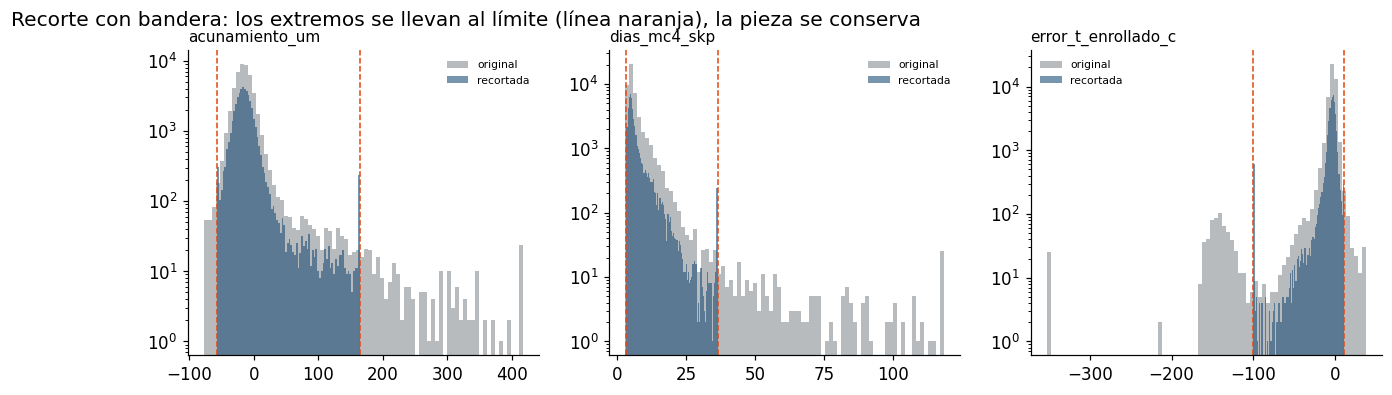

In [14]:
# Figura: qué hace el recorte en tres variables con colas largas (entrenamiento).
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
crudo = {'acunamiento_um': num(M('Acuñamiento Salida')), 'dias_mc4_skp': (L['Fecha Inicio'] - L[M('Fecha Fin')]).dt.total_seconds() / 86400,
         'error_t_enrollado_c': num(M('Temp Enrollado Real')) - num(M('Temp Enrollado Obj'))}
for a, (c, s) in zip(ax, crudo.items()):
    s = s[ENTR]; lo, hi = umbrales[c]
    rng_ = s.quantile([.0005, .9995])
    a.hist(s.clip(*rng_), 80, color=COLORES['gris'], alpha=.6, label='original')
    a.hist(B.loc[ENTR, c], 80, color=COLORES['azul'], alpha=.6, label='recortada')
    for v in (lo, hi): a.axvline(v, color=COLORES['naranja'], ls='--', lw=1)
    a.set_title(c, fontsize=10); a.set_yscale('log'); a.legend(fontsize=7)
fig.suptitle('Recorte con bandera: los extremos se llevan al límite (línea naranja), la pieza se conserva', x=.01, ha='left')
guardar(fig, '03_recorte'); plt.show()

## F. Conclusiones de la etapa

### Lo que quedó construido
- **`data/analitica/base_analitica.parquet`:** una fila por pieza ligada, con respuestas, predictores por bloque, controles, agrupaciones, etiquetas B, banderas de extremo y de faltante, población y pliegue.
- **`resultados/03_diccionario_derivadas.csv`:** cada variable con su bloque, unidad, fórmula, razón física, momento en que se conoce, % de faltantes y regla de recorte.
- **`resultados/03_umbrales_extremos.csv`:** los límites calculados en entrenamiento, para aplicarlos igual en cualquier dato nuevo.
- **`cargar_base_analitica()`** en `src/ternium.py`: los notebooks siguientes leen la base con una línea.

### Decisiones tomadas
| Tema | Decisión |
|---|---|
| Prueba final | Piezas que entraron al Skinpass desde el 1 de noviembre de 2025; marcadas con `en_prueba` |
| Validación | 5 pliegues por Programa MC4 en entrenamiento; ningún programa ni rollo se reparte |
| Extremos | Recorte a p0.5-p99.5 del entrenamiento + bandera; enrollado frío (< −100 °C) como evento propio |
| Valores imposibles | Corona fuera de 0-1,000 µm y descarga a 0 °C pasan a faltante |
| Faltantes | No se imputan en la base; bandera si > 1 %; imputación dentro de cada modelo |
| Fuga | Variables posteriores al dictamen no se guardan; las del Skinpass son respuesta o mediador |
| No construidas | Desajuste corona banda-rodillo (unidad no documentada), fuerza específica, toneladas en campaña, F2-F7 |

### Limitaciones
- Cuatro variables no tienen unidad documentada (taper, canteo, corona del rodillo y tiempo de estancia). Se usan como están, sin combinarlas con otras.
- `t_descarga_horno_c` tiene 5.3 % de faltantes en el periodo de prueba contra 0.07 % en entrenamiento: algo cambió en ese registro en noviembre-diciembre. Si un modelo depende de ella, su desempeño en prueba puede bajar por eso y no por el proceso.
- Los programas que cruzan la frontera de prueba quedan marcados; su efecto se revisará en la evaluación final.
- B2 · forma tiene pocos eventos por pliegue.

### Qué sigue
El **Notebook 04** modela ΔBending y ΔFuerza con modelos mixtos y GBDT, con modelos anidados (controles → + MC4 → + Skinpass → completo), para responder **cuánto explica cada bloque**.